In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [68]:
df = pd.read_csv('../CSVs/bebidas_gaseosas.csv')

In [69]:
# Variable de entrada 
x = df.iloc[0:10,0].values
# Variable objetivo
y = df.iloc[0:10,1].values

print(f'x: {x}')
print(f'y: {y}')

x: [55 58 64 68 70 75 80 84]
y: [340 335 410 460 450 610 735 780]


In [70]:
# Inicializar los escaladores
mms_x = MinMaxScaler()
mms_y = MinMaxScaler()

# Ajustar y transformar los datos
x_train = mms_x.fit_transform(x.reshape(-1,1))
y_train = mms_y.fit_transform(y.reshape(-1,1))

print(x_train)
print(y_train)

[[0.        ]
 [0.10344828]
 [0.31034483]
 [0.44827586]
 [0.51724138]
 [0.68965517]
 [0.86206897]
 [1.        ]]
[[0.01123596]
 [0.        ]
 [0.16853933]
 [0.28089888]
 [0.25842697]
 [0.61797753]
 [0.8988764 ]
 [1.        ]]


In [71]:
m = x_train.shape[0]
print(f'm: {m}')

m: 8


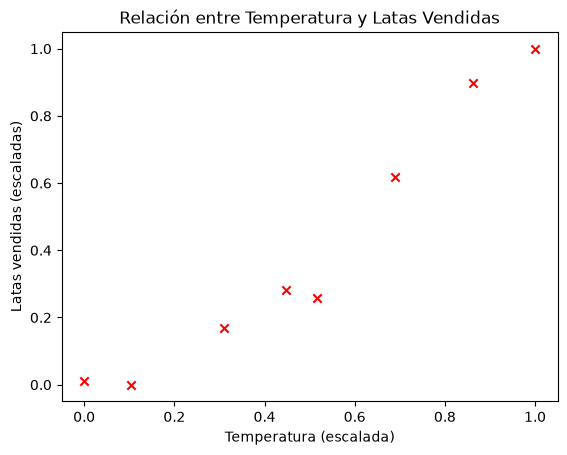

In [72]:
plt.scatter(x_train, y_train, color='red', marker='x')
plt.title('Relación entre Temperatura y Latas Vendidas')
plt.xlabel('Temperatura (escalada)')
plt.ylabel('Latas vendidas (escaladas)')
plt.show()

In [73]:
def compute_cost(x, y, w, b):
    """
    Calcula la función de costo (error cuadrático medio) de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos de entrada, m ejemplos.
        y (ndarray (m,)): Valores objetivo.
        w,b (scalar): Parámetros del modelo.
    Returns:
        costo (float): J(w,b) = (1/2m) * Σ (f_wb(x_i) - y_i)^2
    """
    m = x.shape[0]
    f_wb = w * x + b
    return np.sum((f_wb - y) ** 2) / (2 * m)

w = 0.6, b = +0.4 -> costo = 0.0583
w = 0.8, b = +0.1 -> costo = 0.0121
w = 1.2, b = -0.2 -> costo = 0.0053
w = 1.0, b = -0.1 -> costo = 0.0046


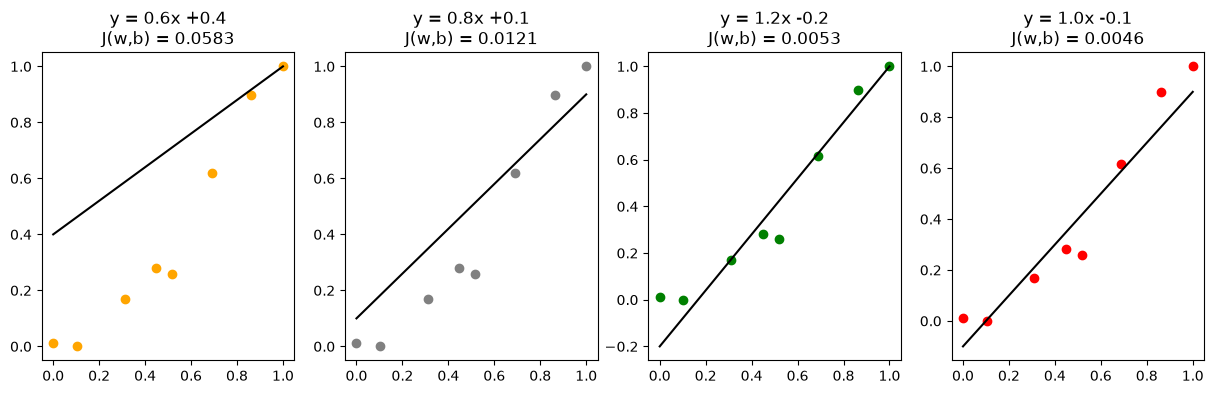

In [74]:
# Ecuaciones candidatas (w, b)
candidatos = [(0.6, 0.4), (0.8, 0.1), (1.2, -0.2), (1.0, -0.1)]
colores = ['orange', 'gray', 'green', 'red']

fig, axs = plt.subplots(1,4, figsize=(15,4))

for ax, (w_c, b_c), color in zip(axs, candidatos, colores):
    y_p = w_c * x_train + b_c
    costo = compute_cost(x_train, y_train, w_c, b_c)
    ax.scatter(x_train, y_train, color=color)
    ax.plot(x_train, y_p, color='black')
    ax.set_title(f'y = {w_c}x {b_c:+}\nJ(w,b) = {costo:.4f}')
    print(f'w = {w_c}, b = {b_c:+} -> costo = {costo:.4f}')

plt.show()

In [75]:
def compute_model_output(x, w, b):
    """
    Calcula la predicción de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos, m ejemplos.
        w,b (scalar): Parámetros del modelo.
    Returns:
        f_wb (ndarray (m,)): Predicciones del modelo.
    """
    return w * x +b

In [76]:
# Valores óptimos (menor costo entre los candidatos)
w = 1.0
b = -0.1
f_wb = compute_model_output(x_train, w, b)
print(f'Costo con w={w}, b={b}: {compute_cost(x_train, y_train, w, b):.4f}')

Costo con w=1.0, b=-0.1: 0.0046


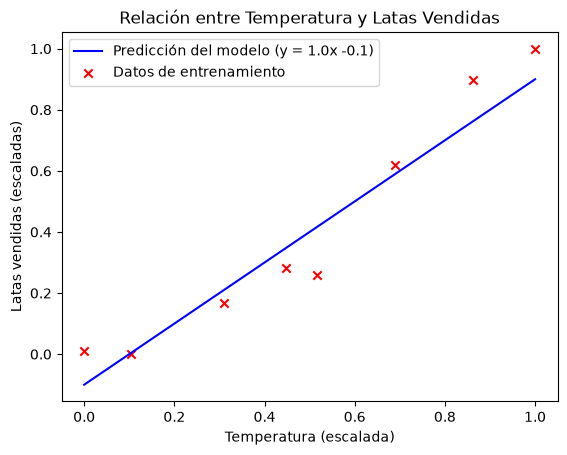

In [77]:
plt.plot(x_train, f_wb, color='blue', label=f'Predicción del modelo (y = {w}x {b:+})')
plt.scatter(x_train, y_train, color='red', marker='x', label='Datos de entrenamiento')
plt.title('Relación entre Temperatura y Latas Vendidas')
plt.xlabel('Temperatura (escalada)')
plt.ylabel('Latas vendidas (escaladas)')
plt.legend()
plt.show()

In [78]:
x_i_1 = 45
temperatura_escalada_1 = mms_x.transform(np.array([[x_i_1]]))
print(f'Temperatura escalada: {temperatura_escalada_1}')

prediccion_1 = compute_model_output(temperatura_escalada_1, w, b)
print(f'Predicción (escalada): {prediccion_1}')

latas_1 = mms_y.inverse_transform(prediccion_1)
print(f'Predicción: {latas_1[0,0]:.0f} latas vendidas a {x_i_1}°')

Temperatura escalada: [[-0.34482759]]
Predicción (escalada): [[-0.44482759]]
Predicción: 137 latas vendidas a 45°


In [79]:
x_i_2 = 95
temperatura_escalada_2 = mms_x.transform(np.array([[x_i_2]]))
print(f'Temperatura escalada: {temperatura_escalada_2}')

prediccion_2 = compute_model_output(temperatura_escalada_2, w, b)
print(f'Predicción (escalada): {prediccion_2}')

latas_2 = mms_y.inverse_transform(prediccion_2)
print(f'Predicción: {latas_2[0,0]:.0f} latas vendidas a {x_i_2}°')

Temperatura escalada: [[1.37931034]]
Predicción (escalada): [[1.27931034]]
Predicción: 904 latas vendidas a 95°


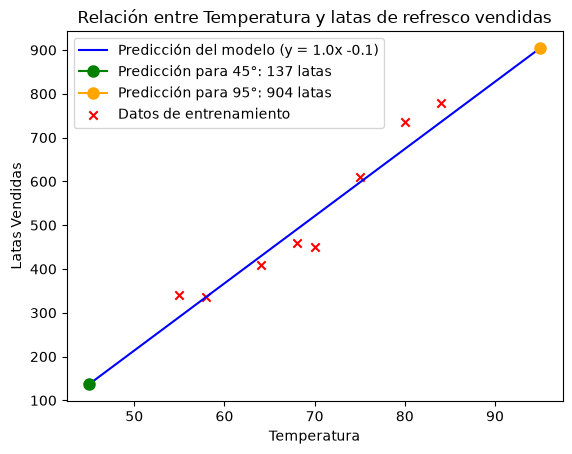

In [80]:
# Graficar en unidades reales (temperatura y latas), deshaciendo el escalado
x_real = mms_x.inverse_transform(x_train)
y_real = mms_y.inverse_transform(y_train)

# Recta del modelo extendida para cubrir también las temperaturas predichas
x_linea = np.linspace(x_i_1, x_i_2, 100).reshape(-1,1)
y_linea = mms_y.inverse_transform(compute_model_output(mms_x.transform(x_linea), w, b))

plt.plot(x_linea, y_linea, color='blue', label=f'Predicción del modelo (y = {w}x {b:+})')
plt.plot(x_i_1, latas_1[0,0], color='green', marker='o', markersize=8, label=f'Predicción para {x_i_1}°: {latas_1[0,0]:.0f} latas')
plt.plot(x_i_2, latas_2[0,0], color='orange', marker='o', markersize=8, label=f'Predicción para {x_i_2}°: {latas_2[0,0]:.0f} latas')
plt.scatter(x_real, y_real, color='red', marker='x', label='Datos de entrenamiento')
plt.title('Relación entre Temperatura y latas de refresco vendidas')
plt.xlabel('Temperatura')
plt.ylabel('Latas Vendidas')
plt.legend()
plt.show()